<a href="https://colab.research.google.com/github/dynamicwebpaige/gemini-and-gemma-examples/blob/main/Gemini_Batch_API_with_Hugging_Face_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import json
import signal
from datasets import load_dataset
from google import genai
from google.genai import types
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ADD AN API KEY
client = genai.Client(api_key="GEMINI_API_KEY")

# LOAD DATASET
ds = load_dataset("openai/openai_humaneval", split="test")

# PREPARE JSONL FILE
jsonl_filename = "humaneval_input.jsonl"

print(f"Generating {jsonl_filename}...")
with open(jsonl_filename, "w") as f:
    for item in ds:
        custom_id = item["task_id"].replace("/", "_")

        # We prompt the model to complete the function
        prompt_text = (
            f"Complete the following Python function. "
            f"Provide ONLY the code, no explanation.\n\n{item['prompt']}"
        )

        entry = {
            "custom_id": custom_id,
            "method": "generateContent",
            "request": {
                "contents": [{"role": "user", "parts": [{"text": prompt_text}]}],
                "generation_config": {"temperature": 1.0}
            }
        }
        f.write(json.dumps(entry) + "\n")

# 4. UPLOAD FILE WITH EXPLICIT MIME TYPE
print("Uploading file to Gemini API...")
uploaded_file = client.files.upload(
    file=jsonl_filename,
    config={'mime_type': 'application/jsonl'}
)

print(f"File uploaded: {uploaded_file.name}")

# 5. CREATE BATCH JOB
print("Submitting batch job...")
batch_job = client.batches.create(
    model="gemini-2.5-flash-lite",
    src=uploaded_file.name,
    config=types.CreateBatchJobConfig(display_name="humaneval_batch_job")
)

print(f"Batch Job Created: {batch_job.name}")
print(f"Current Status: {batch_job.state}")

Generating humaneval_input.jsonl...
Uploading file to Gemini API...
File uploaded: files/8f1d1pk92723
Submitting batch job...
Batch Job Created: batches/h2cuwwbyebjt66ssk8uix00ozb13fa32t01n
Current Status: JobState.JOB_STATE_PENDING


In [50]:
# Get the latest status
job = client.batches.get(name=batch_job.name)

if job.state.name == 'JOB_STATE_SUCCEEDED':
    remote_filename = job.dest.file_name
    print(f"Downloading results from: {remote_filename}")

    # Use 'file=' or pass it positionally
    try:
        # Attempt positional first as it's the most compatible
        content_bytes = client.files.download(remote_filename)
    except TypeError:
        # Fallback to the 'file' keyword if positional fails
        content_bytes = client.files.download(file=remote_filename)

    local_results_path = "results.jsonl"
    with open(local_results_path, "wb") as f:
        f.write(content_bytes)

    print(f"✅ Results saved locally to: {local_results_path}")
else:
    print(f"Job is not ready. Current state: {job.state}")

✅ Results saved locally to: results.jsonl


In [51]:
# Define a timeout handler
class TimeoutException(Exception):
    pass

def timeout_handler(signum, frame):
    raise TimeoutException()

def run_humaneval_eval(results_file, original_dataset):
    print("Starting Evaluation with Timeouts...\n")

    # Register the signal handler
    signal.signal(signal.SIGALRM, timeout_handler)

    # Map results by custom_id
    results_map = {}
    with open(results_file, 'r') as f:
        for line in f:
            data = json.loads(line)
            cid = data['custom_id']
            try:
                text = data['response']['candidates'][0]['content']['parts'][0]['text']
                if "```python" in text:
                    text = text.split("```python")[1].split("```")[0]
                elif "```" in text:
                    text = text.split("```")[1].split("```")[0]
                results_map[cid] = text.strip()
            except (KeyError, IndexError):
                results_map[cid] = ""

    passed = 0
    total = len(original_dataset)

    for item in original_dataset:
        cid = item["task_id"].replace("/", "_")

        if cid not in results_map or not results_map[cid]:
            print(f"❌ {item['task_id']}: No code generated.")
            continue

        generated_code = results_map[cid]

        # Assemble script
        if item['entry_point'] not in generated_code:
            test_script = f"{item['prompt']}\n{generated_code}\n\n{item['test']}\ncheck({item['entry_point']})"
        else:
            test_script = f"{generated_code}\n\n{item['test']}\ncheck({item['entry_point']})"

        # EXECUTION WITH TIMEOUT
        try:
            # Set alarm for 2 seconds
            signal.alarm(2)

            exec_globals = {}
            exec(test_script, exec_globals)

            # Disable alarm if successful
            signal.alarm(0)
            passed += 1
            print(f"✅ {item['task_id']}: Passed")

        except TimeoutException:
            print(f"❌ {item['task_id']}: FAILED (Infinite Loop/Timeout)")
        except Exception as e:
            signal.alarm(0) # Disable alarm on error
            print(f"❌ {item['task_id']}: FAILED ({type(e).__name__})")

    print(f"\n{'='*40}")
    print(f"FINAL HUMAN-EVAL SCORE: {passed}/{total} ({(passed/total)*100:.2f}%)")
    print(f"{'='*40}")

# Run the evaluation
run_humaneval_eval("results.jsonl", ds)

Starting Evaluation with Timeouts...

✅ HumanEval/0: Passed
✅ HumanEval/1: Passed
✅ HumanEval/2: Passed
✅ HumanEval/3: Passed
✅ HumanEval/4: Passed
✅ HumanEval/5: Passed
✅ HumanEval/6: Passed
✅ HumanEval/7: Passed
✅ HumanEval/8: Passed
✅ HumanEval/9: Passed
✅ HumanEval/10: Passed
✅ HumanEval/11: Passed
✅ HumanEval/12: Passed
✅ HumanEval/13: Passed
✅ HumanEval/14: Passed
✅ HumanEval/15: Passed
✅ HumanEval/16: Passed
✅ HumanEval/17: Passed
✅ HumanEval/18: Passed
✅ HumanEval/19: Passed
✅ HumanEval/20: Passed
✅ HumanEval/21: Passed
✅ HumanEval/22: Passed
✅ HumanEval/23: Passed
✅ HumanEval/24: Passed
✅ HumanEval/25: Passed
✅ HumanEval/26: Passed
✅ HumanEval/27: Passed
✅ HumanEval/28: Passed
✅ HumanEval/29: Passed
✅ HumanEval/30: Passed
✅ HumanEval/31: Passed
❌ HumanEval/32: FAILED (IndentationError)
✅ HumanEval/33: Passed
✅ HumanEval/34: Passed
✅ HumanEval/35: Passed
✅ HumanEval/36: Passed
✅ HumanEval/37: Passed
✅ HumanEval/38: Passed
✅ HumanEval/39: Passed
✅ HumanEval/40: Passed
✅ HumanEva

Processing results for visualization...


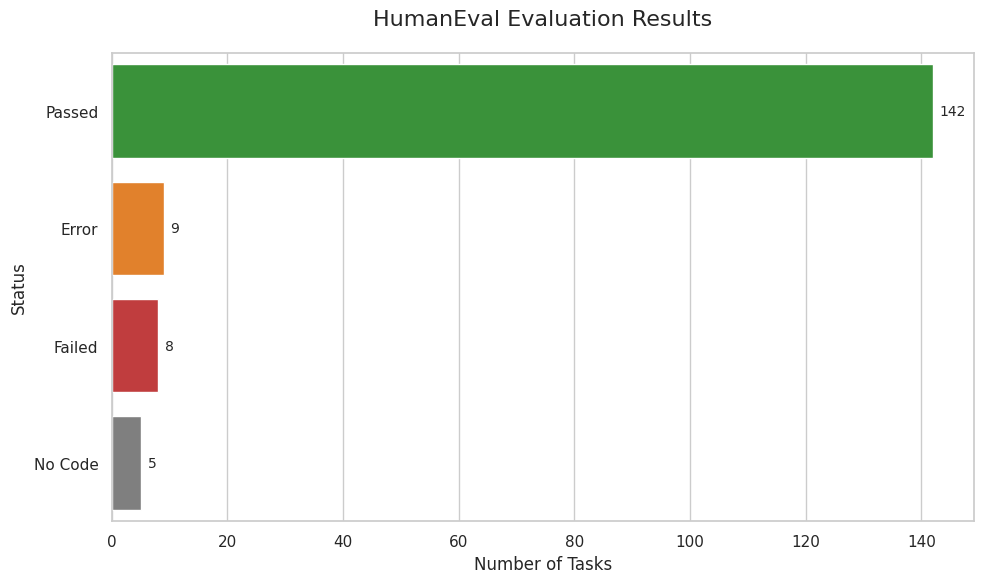


Summary Statistics:
 Status  Count  Percentage
 Passed    142       86.59
  Error      9        5.49
 Failed      8        4.88
No Code      5        3.05


In [52]:
# 1. Gather Data
results_data = []
results_map = {}

# Load results from file
with open("results.jsonl", 'r') as f:
    for line in f:
        data = json.loads(line)
        cid = data['custom_id']
        try:
            text = data['response']['candidates'][0]['content']['parts'][0]['text']
            if "```python" in text:
                text = text.split("```python")[1].split("```")[0]
            elif "```" in text:
                text = text.split("```")[1].split("```")[0]
            results_map[cid] = text.strip()
        except (KeyError, IndexError):
            results_map[cid] = ""

# Register signal
signal.signal(signal.SIGALRM, timeout_handler)

print("Processing results for visualization...")

for item in ds:
    cid = item["task_id"].replace("/", "_")

    status = "Unknown"
    if cid not in results_map or not results_map[cid]:
        status = "No Code"
    else:
        generated_code = results_map[cid]

        # Construct test script
        if item['entry_point'] not in generated_code:
            test_script = f"{item['prompt']}\n{generated_code}\n\n{item['test']}\ncheck({item['entry_point']})"
        else:
            test_script = f"{generated_code}\n\n{item['test']}\ncheck({item['entry_point']})"

        try:
            # Short timeout for quick verification
            signal.alarm(1)
            exec_globals = {}
            exec(test_script, exec_globals)
            signal.alarm(0)
            status = "Passed"
        except TimeoutException:
            status = "Timeout"
        except AssertionError:
            signal.alarm(0)
            status = "Failed"
        except Exception as e:
            signal.alarm(0)
            status = "Error"

    results_data.append({"task_id": item["task_id"], "status": status})

# 2. Create DataFrame
df = pd.DataFrame(results_data)

# 3. Visualize
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Define colors
colors = {"Passed": "#2ca02c", "Failed": "#d62728", "Error": "#ff7f0e", "Timeout": "#9467bd", "No Code": "#7f7f7f"}

# Plot
ax = sns.countplot(y="status", data=df, hue="status", palette=colors, legend=False,
                   order=df['status'].value_counts().index)

plt.title("HumanEval Evaluation Results", fontsize=16, pad=20)
plt.xlabel("Number of Tasks", fontsize=12)
plt.ylabel("Status", fontsize=12)

# Add labels to bars
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10)

plt.tight_layout()
plt.show()

# 4. Print Summary Table
summary = df['status'].value_counts().reset_index()
summary.columns = ['Status', 'Count']
summary['Percentage'] = (summary['Count'] / len(df) * 100).round(2)
print("\nSummary Statistics:")
print(summary.to_string(index=False))